<ErrorbarContainer object of 3 artists>

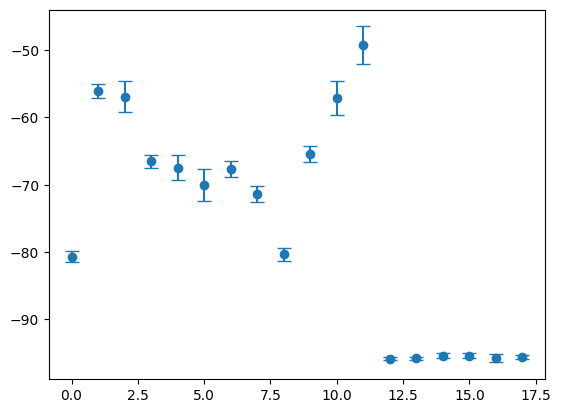

In [4]:
import wandb
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np

api = wandb.Api()

# NT Benchmark scores from the paper, expressed as mean and variability
paper_nt_benchmark_scores = {
    "H3": (81.50, 0.80),
    "H3K4me1": (56.60, 1.01),
    "H3K4me2": (57.45, 2.27),
    "H3K4me3": (67.15, 0.93),
    "H3K9ac": (68.10, 1.91),
    "H3K14ac": (70.71, 2.32),
    "H3K36me3": (68.31, 1.19),
    "H3K79me3": (72.08, 1.23),
    "H4": (81.12, 0.93),
    "H4ac": (66.10, 1.20),
    "enhancers": (57.60, 2.52),
    "enhancers_types": (49.75, 2.82),
    "promoter_all": (96.82, 0.22),
    "promoter_no_tata": (96.76, 0.21),
    "promoter_tata": (96.34, 0.38),
    "splice_sites_acceptors": (96.23, 0.41),
    "splice_sites_donors": (96.62, 0.61),
    "splice_sites_all": (96.33, 0.31),
}

runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "jobType": "nt_benchmark_old",
    "group": "baseline_paper"
})

def build_runs_scores(runs, metrics):
    runs_scores = {}
    for r in runs:
        dataset_name = r.config["dataset"]["dataset_name"]
        for metric in metrics:
            score = r.summary.get(metric)
            if score is not None:
                break
        
        if score is None:
            raise ValueError(f"Run {r.name} does not have any of the metrics {metrics} in its summary.")
        
        runs_scores[dataset_name] = score
    return runs_scores

runs_scores = build_runs_scores(runs, ["val/f1_macro", "val/mcc"])

means = np.array([score[0] for score in paper_nt_benchmark_scores.values()])
variations = [score[1] for score in paper_nt_benchmark_scores.values()]
runs_scores = np.array([runs_scores[dataset_name] for dataset_name in paper_nt_benchmark_scores.keys()])

plt.errorbar(
    range(len(runs_scores)), runs_scores - means, yerr=variations, fmt="o", capsize=5, label="ConvNova Paper Scores"
)

AttributeError: 'BarContainer' object has no attribute 'bar_label'

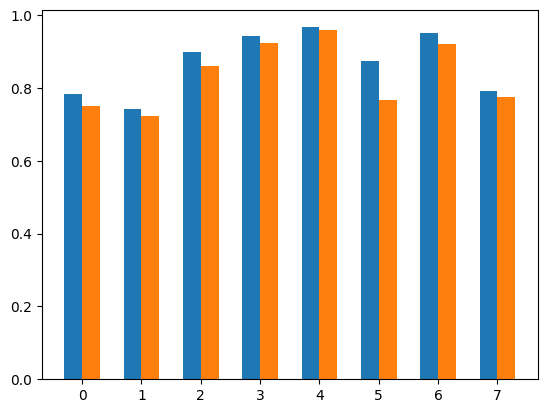

In [5]:
paper_genomic_benchmark_scores = {
    "dummy_mouse_enhancers_ensembl": (0.784, 0.009),
    "human_enhancers_cohn": (0.743, 0.005),
    "human_enhancers_ensembl": (0.900, 0.004),
    "demo_coding_vs_intergenomic_seqs": (0.943, 0.001),
    "demo_human_or_worm": (0.967, 0.002),
    "human_ensembl_regulatory": (0.873, 0.002),
    "human_nontata_promoters": (0.951, 0.003),
    "human_ocr_ensembl": (0.793, 0.004),
}

runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "jobType": "genomic_benchmark",
    "group": "baseline_paper"
})

runs_scores = build_runs_scores(runs, ["val/accuracy"])
ordered_paper_scores = [v[0] for v in paper_genomic_benchmark_scores.values()]
ordered_runs_scores = [runs_scores[dataset_name] for dataset_name in paper_genomic_benchmark_scores.keys()]

width = 0.3
x = np.arange(len(ordered_paper_scores))
plt.bar(x - width / 2, ordered_paper_scores, width, capsize=5, label="ConvNova Paper Scores")
bars = plt.bar(x + width / 2, ordered_runs_scores, width, capsize=5, label="Our Runs Scores")
bars.bar_label([f"{round(score)}" for score in ordered_runs_scores], label_type="center", fontsize=8)

plt.xticks(x, paper_genomic_benchmark_scores.keys(), rotation=90)
plt.legend()